# Project Data Mining — Conference Popularity & Association Pattern Mining (DBLP)

Alur: **extraction → preprocessing → conference popularity → transactional database → Apriori & FP-Growth → association rules → perbandingan performa → analisis temporal → kesimpulan**.

- **Sumber data:** DBLP — <https://dblp.org/xml/dblp.xml.gz> (+ `dblp.dtd`), diunduh **19 November 2026**.
- **Cakupan:** elemen `inproceedings` (konferensi & workshop) seluruh bidang Computer Science, tahun **2015–2025**.
- **Algoritma:** Apriori & FP-Growth memakai library **mlxtend** (diizinkan asisten). Implementasi buatan sendiri disertakan sebagai validasi silang.
- Item transaksi = **konferensi/venue** (akronim dari key DBLP, mis. `conf/aaai/...` → `AAAI`).

In [1]:
import gzip, os, re, time, unicodedata, csv, math, json, warnings
from collections import Counter
from itertools import combinations
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from lxml import etree
from scipy import sparse
from scipy.stats import spearmanr
from mlxtend.frequent_patterns import apriori as ml_apriori, fpgrowth as ml_fpgrowth, association_rules as ml_rules
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"; RAW.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)

Y0, Y1 = 2015, 2025
SUPPORTS = [0.001, 0.005, 0.01, 0.02]          # Task 4 (0,1% / 0,5% / 1% / 2%)
MIN_CONF = 0.5                                  # Task 5
PERIODS = [(2015, 2017), (2018, 2020), (2021, 2023), (2024, 2025)]
TEMPORAL_SUPPORT = 0.001                        # bagian temporal (lihat catatan di bagian 12)
RULE_METRICS = ["antecedent support", "consequent support", "support", "confidence", "lift"]
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 200)

## 1. Data Extraction
`dblp.xml.gz` dan `dblp.dtd` diletakkan di `data/raw/`. File XML dibaca **streaming** (`iterparse`) agar tidak memenuhi memori; hanya `inproceedings` tahun 2015–2025 yang disimpan ke CSV. Sel ini dilewati jika CSV sudah ada.

In [2]:
CSV = RAW / "inproceedings_2015_2025.csv"

def extract(xml_gz, out_csv):
    cwd = os.getcwd(); os.chdir(xml_gz.parent)          # dblp.dtd dicari relatif terhadap file XML
    n_all = n_kept = 0
    try:
        with gzip.open(xml_gz, "rb") as src, open(out_csv, "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f); w.writerow(["key", "authors", "title", "year", "booktitle", "pages"])
            for _, el in etree.iterparse(src, events=("end",), tag="inproceedings",
                                         load_dtd=True, resolve_entities=True, huge_tree=True):
                n_all += 1
                year = (el.findtext("year") or "").strip()
                if year.isdigit() and Y0 <= int(year) <= Y1:
                    t = el.find("title")
                    w.writerow([el.get("key"), "|".join((a.text or "").strip() for a in el.findall("author")),
                                "".join(t.itertext()) if t is not None else "", year,
                                (el.findtext("booktitle") or "").strip(), (el.findtext("pages") or "").strip()])
                    n_kept += 1
                el.clear()
                while el.getprevious() is not None: del el.getparent()[0]
    finally:
        os.chdir(cwd)
    print(f"Total inproceedings di DBLP (semua tahun): {n_all:,} | disimpan 2015-2025: {n_kept:,}")

if not CSV.exists():
    extract(RAW / "dblp.xml.gz", CSV)
else:
    print("CSV sudah ada:", CSV, f"({CSV.stat().st_size/1e6:.0f} MB)")

CSV sudah ada: E:\SEMESTER_7\data mining\tubez\data\raw\inproceedings_2015_2025.csv (373 MB)


## 2. Data Understanding (Task 1.1)

In [3]:
head = pd.read_csv(CSV, dtype=str, keep_default_na=False, nrows=5)
display(head)
keys = pd.read_csv(CSV, usecols=["key"], dtype=str)["key"]
print("Jumlah record (inproceedings 2015-2025):", f"{len(keys):,}")
print("Atribut:", list(head.columns), "-> key, authors (dipisah '|'), title, year, booktitle (nama proceeding), pages")
print("Jenis publikasi berdasarkan awalan key (conf/ = konferensi/workshop):")
print(keys.str.split("/").str[0].value_counts().to_string())
del keys

,key,authors,title,year,booktitle,pages
0,conf/dac/RoquetSRTSK24,Lucas Roquet|Fernando Fernandes dos Santos|Paolo Rech|Marcello Tra...,Cross-Layer Reliability Evaluation and Efficient Hardening of Larg...,2024,DAC,291:1-291:6
1,conf/dac/LiuZWCYHYJ22,Fangxin Liu|Wenbo Zhao 0005|Zongwu Wang|Yongbiao Chen|Tao Yang 003...,SATO: spiking neural network acceleration via temporal-oriented da...,2022,DAC,1105-1110
2,conf/dac/AhnYLHKP20,Sunwoo Ahn|Hayoon Yi|Younghan Lee 0001|Whoi Ree Ha|Giyeol Kim|Yunh...,Hawkware: Network Intrusion Detection based on Behavior Analysis w...,2020,DAC,1-6
3,conf/dac/ParkPVC24,Chanwoo Park|Junghwan Park|Premkumar Vincent|Hyunbo Cho,Accelerating DTCO with a Sample-Efficient Active Learning Framewor...,2024,DAC,132:1-132:6
4,conf/dac/PuL0HLC024,Yuan Pu 0001|Fangzhou Liu 0005|Yu Zhang 0189|Zhuolun He|Yibo Lin|K...,Lesyn: Placement-aware Logic Resynthesis for Non-Integer Multiple-...,2024,DAC,116:1-116:6


Jumlah record (inproceedings 2015-2025): 2,004,202
Atribut: ['key', 'authors', 'title', 'year', 'booktitle', 'pages'] -> key, authors (dipisah '|'), title, year, booktitle (nama proceeding), pages
Jenis publikasi berdasarkan awalan key (conf/ = konferensi/workshop):


key
conf        2001039
journals       3123
books            40


## 3. Preprocessing (Task 1.2–1.3)
Dikerjakan per-chunk agar hemat memori. Tahapan dan alasannya:

| Tahap | Alasan |
|---|---|
| Pilih publikasi konferensi & workshop (key `conf/*`) | Soal hanya meminta `inproceedings`; key `conf/` memastikan venue berupa konferensi. |
| Buang missing values (author, title, year, venue kosong) | Tanpa author/venue sebuah publikasi tidak bisa menjadi item transaksi. |
| Normalisasi nama author | DBLP menambah nomor disambiguasi (`Wei Wang 0001`) — dihapus agar satu nama tidak terpecah; spasi dirapikan dan unicode dinormalisasi (NFKC); author ganda dalam satu paper dibuang. |
| Normalisasi nama venue | Nama venue = akronim pada key DBLP (`conf/aaai/..` → `AAAI`), karena `booktitle` penulisannya bervariasi (tahun/ordinal ikut tertulis). |
| Hapus duplikat | Duplikat berdasarkan `key` yang sama, atau kombinasi (judul ter-normalisasi, tahun, venue) yang sama. |
| Pastikan atribut tahun valid | `year` dikonversi ke integer dan dibatasi 2015–2025. |

In [4]:
SUF = re.compile(r"\s+\d{4}$")
def norm_author(a):
    return re.sub(r"\s+", " ", SUF.sub("", unicodedata.normalize("NFKC", a))).strip()
def clean_authors(s):
    seen, out = set(), []
    for a in s.split("|"):
        a = norm_author(a)
        if a and a not in seen:
            seen.add(a); out.append(a)
    return "|".join(out)

CLEAN = ROOT / "data" / "clean_papers.pkl"; LOGF = ROOT / "data" / "clean_log.json"
ARR = ROOT / "data" / "pairs_cache.npz"; LEAN = ROOT / "data" / "clean_lean.pkl"; NAMES = ROOT / "data" / "author_names.txt"
if ARR.exists() and LEAN.exists() and LOGF.exists():
    clean = pd.read_pickle(LEAN); log = json.loads(LOGF.read_text())
    print("Memuat cache ringan hasil preprocessing (tanpa kolom author).")
elif CLEAN.exists() and LOGF.exists():
    clean = pd.read_pickle(CLEAN); log = json.loads(LOGF.read_text())
    print("Memuat hasil preprocessing yang sudah tersimpan.")
else:
    log = Counter(); parts = []
    for ch in pd.read_csv(CSV, dtype=str, keep_default_na=False, chunksize=250_000):
        log["1. Data awal (inproceedings 2015-2025)"] += len(ch)
        ch = ch[ch.key.str.startswith("conf/") & (ch.key.str.count("/") >= 2)].copy()
        ch["venue"] = ch.key.str.split("/").str[1].str.upper()
        log["2. Setelah filter konferensi/workshop"] += len(ch)
        for c in ["authors", "title", "year", "venue"]:
            ch = ch[ch[c].str.strip() != ""]
        ch["authors"] = ch.authors.map(clean_authors); ch = ch[ch.authors != ""]
        ch = ch[ch.year.str.isdigit()].copy(); ch["year"] = ch.year.astype(int); ch = ch[ch.year.between(Y0, Y1)]
        log["3. Setelah hapus missing values"] += len(ch)
        tn = ch.title.str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()
        parts.append(pd.DataFrame({
            "kh": pd.util.hash_pandas_object(ch.key, index=False).values,
            "th": pd.util.hash_pandas_object(tn, index=False).values,
            "venue": ch.venue.values, "year": ch.year.astype("int16").values,
            "workshop": ch.booktitle.str.contains("workshop", case=False, na=False).values,
            "authors": ch.authors.values}))
    clean = pd.concat(parts, ignore_index=True); del parts
    clean = clean.drop_duplicates("kh").drop_duplicates(["th", "year", "venue"]).drop(columns=["kh", "th"]).reset_index(drop=True)
    log["4. Setelah hapus duplikat (data akhir)"] = len(clean); log = dict(log)
    clean.to_pickle(CLEAN); LOGF.write_text(json.dumps(log))

t = pd.Series(log, name="jumlah record").to_frame()
t["terbuang"] = (-t["jumlah record"].diff()).fillna(0).astype(int)
display(t)
print(f"Total data terbuang saat preprocessing: {t['terbuang'].sum():,} record "
      f"({t['terbuang'].sum()/t['jumlah record'].iloc[0]:.2%} dari data awal)")

Memuat cache ringan hasil preprocessing (tanpa kolom author).


,jumlah record,terbuang
1. Data awal (inproceedings 2015-2025),2004202,0
2. Setelah filter konferensi/workshop,2001039,3163
3. Setelah hapus missing values,1998786,2253
4. Setelah hapus duplikat (data akhir),1997196,1590


Total data terbuang saat preprocessing: 7,006 record (0.35% dari data awal)


## 4. Statistik Dataset Setelah Preprocessing (Task 1.4)
Author diubah menjadi ID integer agar transaksi bisa dibangun sebagai matriks sparse (hemat memori).

Total publikasi    :

 1,997,196
Total author unik  : 1,745,848
Total venue unik   : 4,372
Publikasi workshop (booktitle memuat 'workshop'): 58,013
Rata-rata author per publikasi: 3.94


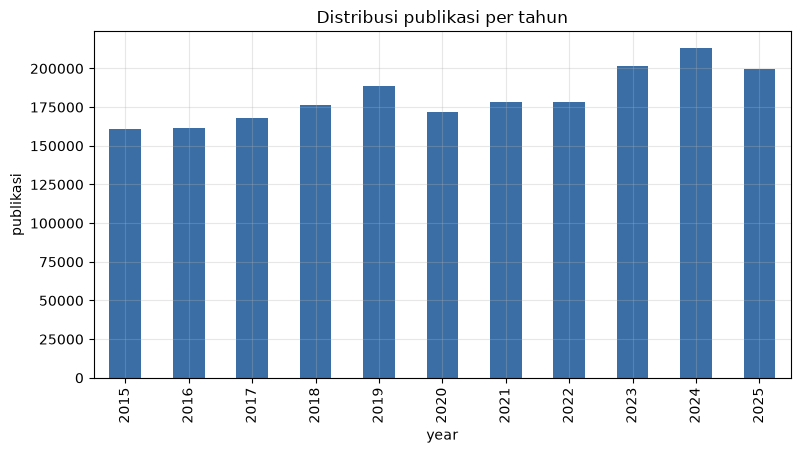

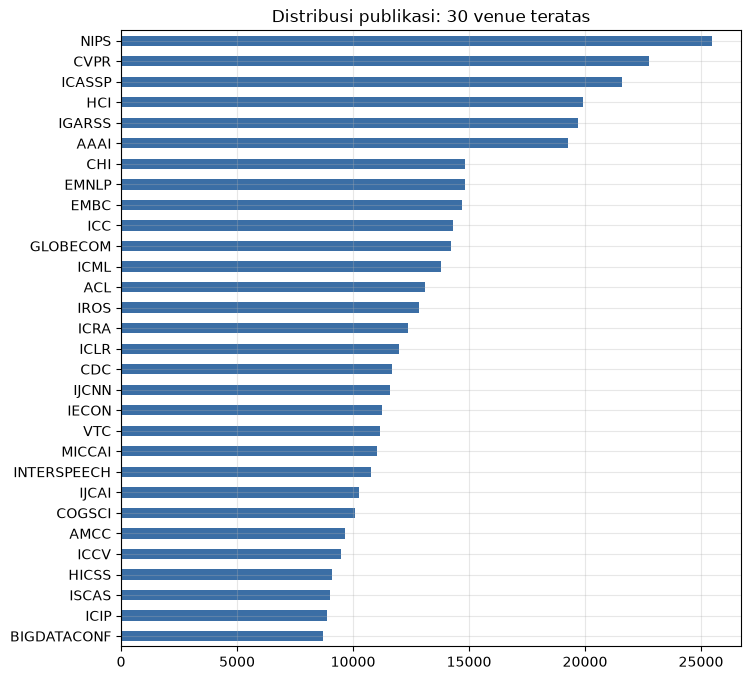

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
publikasi,160792,161645,167765,176306,188429,171769,178162,178066,201382,213328,199552


,NIPS,CVPR,ICASSP,HCI,IGARSS,AAAI,CHI,EMNLP,EMBC,ICC,GLOBECOM,ICML,ACL,IROS,ICRA
publikasi,25455,22750,21606,19912,19685,19274,14832,14813,14676,14329,14243,13778,13098,12851,12361


In [5]:
if "authors" in clean.columns:                  # bangun dari data bersih (sekali saja), lalu simpan cache ringan
    vcode, venues = pd.factorize(clean.venue.values)
    venues = np.asarray(venues).astype(str)
    author_id = {}                               # nama author -> ID integer
    P_aid, P_vc, P_year, P_len = [], [], [], []
    CH = 150_000                                 # diproses per chunk agar hemat memori
    for s in range(0, len(clean), CH):
        sp = clean.authors.iloc[s:s + CH].str.split("|")
        l = sp.map(len).values
        names = [a for lst in sp for a in lst]
        P_aid.append(np.fromiter((author_id.setdefault(a, len(author_id)) for a in names), dtype=np.int32, count=len(names)))
        P_vc.append(np.repeat(vcode[s:s + CH], l).astype(np.int16))
        P_year.append(np.repeat(clean.year.values[s:s + CH], l).astype(np.int16))
        P_len.append(l)
    a_aid, a_vc, a_year = np.concatenate(P_aid), np.concatenate(P_vc), np.concatenate(P_year)   # 1 baris = 1 (paper, author)
    lens = np.concatenate(P_len)
    NAMES.write_text("\n".join(author_id), encoding="utf-8")        # urutan baris = ID author
    n_auth = len(author_id)
    del P_aid, P_vc, P_year, P_len, author_id, sp
    clean = clean.drop(columns="authors")        # kolom author tidak diperlukan lagi
    clean["venue"] = pd.Categorical.from_codes(vcode, categories=venues)   # hemat memori
    np.savez(ARR, a_aid=a_aid, a_vc=a_vc, a_year=a_year, lens=lens, vcode=vcode, venues=venues)
    clean.to_pickle(LEAN)
else:                                            # muat cache ringan
    z = np.load(ARR)
    a_aid, a_vc, a_year, lens, vcode, venues = (z[k] for k in ["a_aid", "a_vc", "a_year", "lens", "vcode", "venues"])
    n_auth = int(a_aid.max()) + 1
n_ven = len(venues)

def author_name(i):
    """Nama author ke-i (dibaca dari file, agar tidak menyimpan 1,7 juta string di memori)."""
    with open(NAMES, encoding="utf-8") as f:
        for k, line in enumerate(f):
            if k == i: return line.rstrip("\n")

print("Total publikasi    :", f"{len(clean):,}")
print("Total author unik  :", f"{n_auth:,}")
print("Total venue unik   :", f"{n_ven:,}")
print("Publikasi workshop (booktitle memuat 'workshop'):", f"{clean.workshop.sum():,}")
print("Rata-rata author per publikasi:", round(lens.mean(), 2))

by_year = clean.groupby("year").size()
by_venue = pd.Series(np.bincount(vcode, minlength=n_ven), index=venues).sort_values(ascending=False)
by_year.plot.bar(color="#3b6ea5", title="Distribusi publikasi per tahun"); plt.ylabel("publikasi"); plt.show()
by_venue.head(30).iloc[::-1].plot.barh(color="#3b6ea5", figsize=(8, 8), title="Distribusi publikasi: 30 venue teratas"); plt.show()
display(by_year.to_frame("publikasi").T); display(by_venue.head(15).to_frame("publikasi").T)
by_year.to_csv(OUT/"t1_pubs_per_year.csv"); by_venue.to_csv(OUT/"t1_pubs_per_venue.csv")

## 5. Conference Popularity Analysis (Task 2)

TOP 10 berdasarkan jumlah publikasi


,n_pubs,n_authors,rank_pubs,rank_authors,selisih_rank
NIPS,25455,53924,1,1,0
CVPR,22750,44111,2,2,0
ICASSP,21606,39200,3,4,-1
HCI,19912,37558,4,6,-2
IGARSS,19685,34071,5,7,-2
AAAI,19274,42440,6,3,3
CHI,14832,29671,7,11,-4
EMNLP,14813,32021,8,8,0
EMBC,14676,38868,9,5,4
ICC,14329,25220,10,18,-8


TOP 10 berdasarkan jumlah author unik


,n_pubs,n_authors,rank_pubs,rank_authors,selisih_rank
NIPS,25455,53924,1,1,0
CVPR,22750,44111,2,2,0
AAAI,19274,42440,6,3,3
ICASSP,21606,39200,3,4,-1
EMBC,14676,38868,9,5,4
HCI,19912,37558,4,6,-2
IGARSS,19685,34071,5,7,-2
EMNLP,14813,32021,8,8,0
ICML,13778,30363,12,9,3
IROS,12851,30329,14,10,4


Irisan kedua top-10: 8 konferensi -> ['AAAI', 'CVPR', 'EMBC', 'EMNLP', 'HCI', 'ICASSP', 'IGARSS', 'NIPS']
Hanya di top-10 publikasi : ['CHI', 'ICC']
Hanya di top-10 author    : ['ICML', 'IROS']
Korelasi Spearman jumlah publikasi vs author unik (semua venue): 0.987


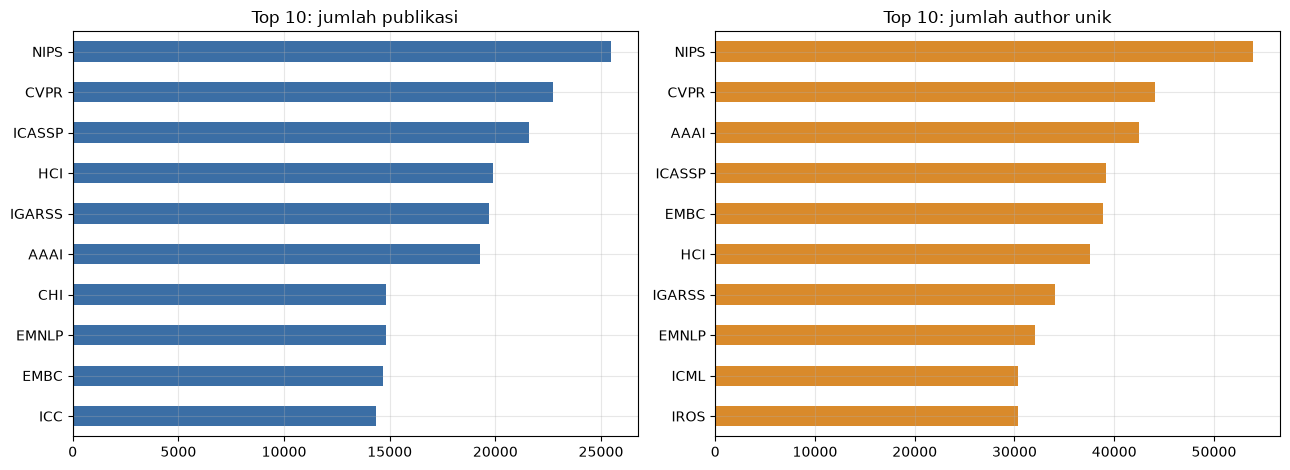

In [6]:
pubs = pd.Series(np.bincount(vcode, minlength=n_ven), index=venues, name="n_pubs")
def uniq_sorted(x):
    """Nilai unik terurut dengan sort in-place (hemat memori dibanding np.unique)."""
    x.sort(); m = np.empty(len(x), dtype=bool); m[0] = True; np.not_equal(x[1:], x[:-1], out=m[1:])
    return x[m]
u = uniq_sorted(a_vc.astype(np.int64) * n_auth + a_aid)                # pasangan unik (venue, author)
authors_v = pd.Series(np.bincount(u // n_auth, minlength=n_ven), index=venues, name="n_authors"); del u
T = pd.concat([pubs, authors_v], axis=1).fillna(0).astype(int)
T["rank_pubs"] = T.n_pubs.rank(ascending=False, method="min").astype(int)
T["rank_authors"] = T.n_authors.rank(ascending=False, method="min").astype(int)
T["selisih_rank"] = T.rank_pubs - T.rank_authors
top_p = T.sort_values("n_pubs", ascending=False).head(10)
top_a = T.sort_values("n_authors", ascending=False).head(10)
print("TOP 10 berdasarkan jumlah publikasi"); display(top_p)
print("TOP 10 berdasarkan jumlah author unik"); display(top_a)
inter = sorted(set(top_p.index) & set(top_a.index))
print(f"Irisan kedua top-10: {len(inter)} konferensi -> {inter}")
print("Hanya di top-10 publikasi :", sorted(set(top_p.index) - set(top_a.index)))
print("Hanya di top-10 author    :", sorted(set(top_a.index) - set(top_p.index)))
print("Korelasi Spearman jumlah publikasi vs author unik (semua venue): %.3f" % spearmanr(T.n_pubs, T.n_authors)[0])
T.sort_values("n_pubs", ascending=False).to_csv(OUT/"t2_venue_ranking.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
top_p.iloc[::-1].n_pubs.plot.barh(ax=ax[0], color="#3b6ea5", title="Top 10: jumlah publikasi")
top_a.iloc[::-1].n_authors.plot.barh(ax=ax[1], color="#d98a2b", title="Top 10: jumlah author unik"); plt.tight_layout(); plt.show()

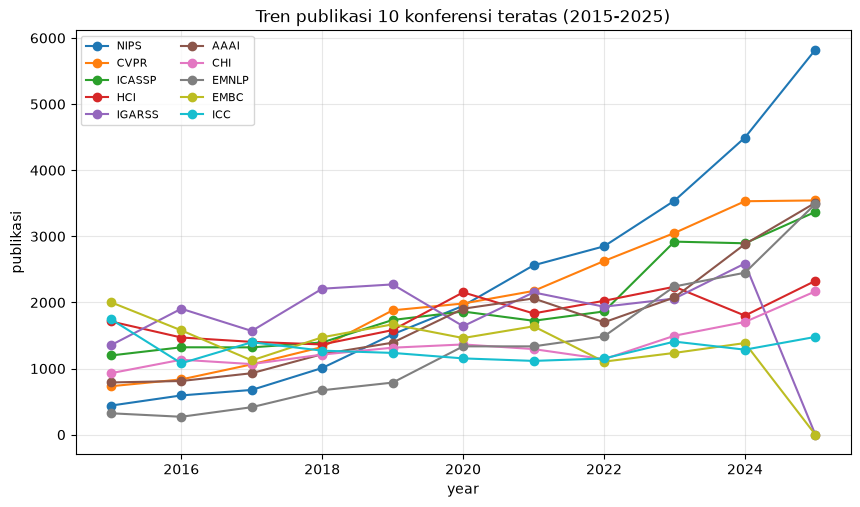

,2015,2025,perubahan %
venue,,,
NIPS,440,5823,1223.4
EMNLP,324,3491,977.5
CVPR,733,3543,383.4
AAAI,790,3508,344.1
ICASSP,1198,3370,181.3
CHI,930,2168,133.1
HCI,1713,2327,35.8
ICC,1747,1479,-15.3
IGARSS,1353,0,-100.0


Pertumbuhan terbesar (rata2 2023-25 vs 2015-17, venue >=500 publikasi):


venue,EMNLP,NIPS,SIGGRAPHA,WANLP,CORL,COMAD,ICLR,ICCCNT
naik %,709.0,710.0,715.0,715.0,845.0,1043.0,2473.0,8488.0


Penurunan terbesar:


venue,ASIST,PCM,ICCCSEC,SOCPROS,OOPSLA,BICA,ICETE,IC-NC
perubahan %,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0


In [7]:
clean_s = clean.astype({"venue": str})
pv = clean_s[clean_s.venue.isin(top_p.index)].pivot_table(index="year", columns="venue", values="workshop", aggfunc="count", fill_value=0)
pv = pv[top_p.index]
pv.plot(marker="o", figsize=(10, 5.5), title="Tren publikasi 10 konferensi teratas (2015-2025)"); plt.ylabel("publikasi")
plt.legend(ncol=2, fontsize=8); plt.show()
chg = pd.DataFrame({"2015": pv.loc[2015], "2025": pv.loc[2025]}); chg["perubahan %"] = ((chg["2025"] / chg["2015"] - 1) * 100).round(1)
display(chg.sort_values("perubahan %", ascending=False))
pv.to_csv(OUT/"t2_trend_top10.csv")
# pertumbuhan terbesar (venue >= 500 publikasi agar tidak bias venue kecil)
big_v = by_venue[by_venue >= 500].index
big = clean_s[clean_s.venue.isin(big_v)]
g = big.pivot_table(index="venue", columns="year", values="workshop", aggfunc="count", fill_value=0)
gr = ((g[[2023, 2024, 2025]].mean(axis=1) / g[[2015, 2016, 2017]].mean(axis=1).replace(0, np.nan) - 1) * 100).dropna().sort_values()
print("Pertumbuhan terbesar (rata2 2023-25 vs 2015-17, venue >=500 publikasi):"); display(gr.tail(8).round(0).to_frame("naik %").T)
print("Penurunan terbesar:"); display(gr.head(8).round(0).to_frame("perubahan %").T)
del big, g, clean_s

## 6. Transactional Database (Task 3)
- **Author-Based**: 1 transaksi = 1 author; item = himpunan konferensi tempat author itu pernah publikasi (2015–2025).
- **Author-Year-Based**: 1 transaksi = (author, tahun); item = konferensi tempat author itu publikasi pada tahun tersebut.

Kedua database disimpan sebagai matriks sparse biner (baris = transaksi, kolom = venue).

In [8]:
def build_csr(tx_code):
    """tx_code = kode transaksi (int64) per baris (paper, author); item = venue. Duplikat dibuang lewat np.unique.
    Return: matriks csr biner, id transaksi unik (terurut)."""
    u = uniq_sorted(tx_code * n_ven + a_vc)                # unik per (transaksi, venue), terurut
    tx, cols = u // n_ven, (u % n_ven).astype(np.int32); del u
    starts = np.flatnonzero(np.r_[True, tx[1:] != tx[:-1]])
    indptr = np.r_[starts, len(tx)].astype(np.int64)
    m = sparse.csr_matrix((np.ones(len(cols), dtype=bool), cols, indptr), shape=(len(starts), n_ven))
    return m, tx[starts]

X_ab, ab_ids = build_csr(a_aid.astype(np.int64))                                   # baris = author
X_ay, ay_ids = build_csr(a_aid.astype(np.int64) * 11 + (a_year.astype(np.int64) - Y0))   # baris = (author, tahun)
ay_year = (ay_ids % 11 + Y0).astype(int); ay_author = ay_ids // 11
del a_aid, a_year, a_vc

def tx_items(X, r): return sorted(venues[X.indices[X.indptr[r]:X.indptr[r + 1]]])

for name, X in [("Author-Based", X_ab), ("Author-Year-Based", X_ay)]:
    sizes = np.diff(X.indptr)
    print(f"{name:18s}: transaksi={X.shape[0]:>9,} | item unik={int((np.asarray(X.sum(axis=0)).ravel() > 0).sum()):,} | "
          f"rata2 item/tx={sizes.mean():.2f} | median={np.median(sizes):.0f} | max={sizes.max()} | "
          f"tx 1-item={np.mean(sizes == 1):.1%}")

Author-Based      : transaksi=1,745,848 | item unik=4,372 | rata2 item/tx=2.74 | median=1 | max=589 | tx 1-item=59.2%
Author-Year-Based : transaksi=3,886,360 | item unik=4,372 | rata2 item/tx=1.66 | median=1 | max=157 | tx 1-item=71.0%


Contoh 10 transaksi Author-Based:


,transaksi,items (konferensi)
0,Fernando Fernandes dos Santos,"DAC, DSN, ETS, HPCA, IOLTS, IPPS, ISVLSI, ITC, SC, VLSI, VTS"
1,Paolo Rech,"ARC, ARCS, CASES, CF, DAC, DATE, DFT, DSN, ETS, HPCA, HPDC, ICCSA,..."
2,Marcello Traiola,"AQTR, CASES, DAC, DATE, DDECS, DFT, DSN, DTIS, ECRTS, ETS, EWDTS, ..."
3,Olivier Sentieys,"AICAS, ARITH, ASAP, BSN, CASES, CCS, COSADE, CVPR, DAC, DASIP, DAT..."
4,Angeliki Kritikakou,"ADHOC-NOW, CASES, DAC, DASIP, DATE, DFT, DSN, ECRTS, EMSOFT, ETS, ..."
5,Fangxin Liu,"AAAI, APCC, APPT, ASPDAC, ASPLOS, DAC, DATE, EMNLP, GLVLSI, HPCA, ..."
6,Wenbo Zhao,"AAAI, ACL, AISTATS, CIPAE, CVPR, DAC, DATE, ECCV, GLOBECOM, GLVLSI..."
7,Zongwu Wang,"AAAI, APPT, ASPDAC, ASPLOS, DAC, DATE, EMNLP, GLVLSI, HPCA, ICASSP..."
8,Yongbiao Chen,"AAAI, DAC, ICASSP, ICCAD, ICCD, ICMCS, MIR, VCIP"
9,Tao Yang,"AAAI, AAIA, ACISICIS, ACIVS, ACL, ADC, AI, AIAM, AIIPCC, AIMECH, A..."


Contoh 10 transaksi Author-Year-Based:


,transaksi,items (konferensi)
0,Fernando Fernandes dos Santos (2019),"ETS, HPCA, IOLTS"
1,Fernando Fernandes dos Santos (2021),"DSN, IOLTS, IPPS, VTS"
2,Fernando Fernandes dos Santos (2022),"IOLTS, ISVLSI, ITC"
3,Fernando Fernandes dos Santos (2023),"ETS, ITC, SC"
4,Fernando Fernandes dos Santos (2024),"DAC, ETS, IOLTS, VLSI, VTS"
5,Paolo Rech (2015),"ARC, CASES, HPCA, HPDC, VTS"
6,Paolo Rech (2017),"ARCS, CF, DFT, DSN, HPCA, MWSCAS, SC"
7,Paolo Rech (2018),"DATE, DSN, LATW, SBAC-PAD, SBCCI, VECPAR, VTS"
8,Paolo Rech (2019),"DATE, DFT, DSN, ETS, HPCA, IOLTS, PDP, SAMOS, SBAC-PAD"
9,Paolo Rech (2020),"DFT, DSN, ETS, IOLTS, IPPS"


,1,2,3,4,5,6,7,8,9,>=10
Author-Based,1033511,277878,131958,77701,50744,35187,25767,19298,14741,79063
Author-Year-Based,2759660,615316,236531,110979,59023,33896,20664,13324,8786,28181


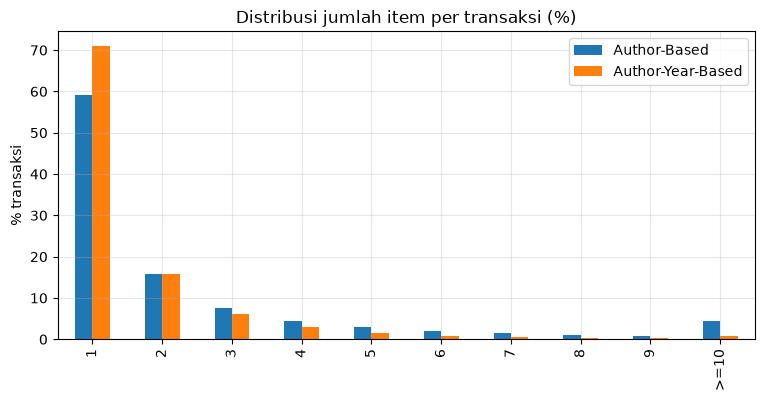

In [9]:
def sample_tx(X, label_fn, k=10, min_items=3):
    rows = [r for r in range(min(X.shape[0], 400_000)) if X.indptr[r + 1] - X.indptr[r] >= min_items][:k]
    return pd.DataFrame({"transaksi": [label_fn(r) for r in rows], "items (konferensi)": [", ".join(tx_items(X, r)) for r in rows]})
print("Contoh 10 transaksi Author-Based:")
s1 = sample_tx(X_ab, lambda r: author_name(int(ab_ids[r]))); display(s1)
print("Contoh 10 transaksi Author-Year-Based:")
s2 = sample_tx(X_ay, lambda r: f"{author_name(int(ay_author[r]))} ({ay_year[r]})"); display(s2)
s1.to_csv(OUT/"t3_sample_author_based.csv", index=False); s2.to_csv(OUT/"t3_sample_author_year_based.csv", index=False)

dist = pd.DataFrame({"Author-Based": pd.Series(np.diff(X_ab.indptr)).clip(upper=10).value_counts().sort_index(),
                     "Author-Year-Based": pd.Series(np.diff(X_ay.indptr)).clip(upper=10).value_counts().sort_index()})
dist.index = [str(i) if i < 10 else ">=10" for i in dist.index]; display(dist.T)
(dist / dist.sum() * 100).plot.bar(figsize=(9, 4), title="Distribusi jumlah item per transaksi (%)"); plt.ylabel("% transaksi"); plt.show()

**Perbedaan & trade-off kedua representasi (Task 3.5–3.6):**

| | Author-Based | Author-Year-Based |
|---|---|---|
| Kelebihan | Satu transaksi merangkum seluruh riwayat author → menangkap hubungan antar-konferensi jangka panjang; item/transaksi lebih banyak sehingga pola co-occurrence lebih kaya. | Memberi dimensi waktu → bisa dipakai analisis temporal; mengurangi efek "author lama" yang menumpuk banyak konferensi; co-occurrence lebih bermakna (publikasi pada tahun yang sama). |
| Keterbatasan | Tidak ada informasi waktu; author senior yang aktif lama punya transaksi besar dan bisa mendominasi pasangan item; sebagian besar author hanya 1 item. | Jumlah transaksi ~2× lebih banyak dan hampir semua berisi 1 item sehingga support pasangan konferensi sangat kecil; pola harus muncul dalam satu tahun yang sama. |

## 7. Algoritma Frequent Pattern Mining
Algoritma utama: **mlxtend** (`apriori`, `fpgrowth`, `association_rules`). Hanya venue yang memenuhi minimum support yang dimasukkan ke matriks (aman karena sifat *anti-monotone*: itemset frequent hanya tersusun dari item frequent). Transaksi yang hanya berisi 1 item frequent juga tidak dimasukkan ke mlxtend karena tidak dapat membentuk itemset ukuran ≥ 2; support 1-itemset dihitung dari seluruh transaksi, dan min support tetap dihitung terhadap **seluruh** transaksi — hasilnya identik, hanya jauh lebih hemat memori. Waktu eksekusi yang dilaporkan adalah waktu algoritma pada data tereduksi ini. Implementasi buatan sendiri (sel berikut) dipakai untuk validasi silang pada bagian 10.

In [10]:
# --- Implementasi sendiri: Apriori, FP-Growth, Association Rules (untuk validasi silang) ---
from collections import Counter, defaultdict
from itertools import combinations
import math


def _weighted(transactions):
    """Gabungkan transaksi identik -> {frozenset: bobot}. Mempercepat counting."""
    c = Counter(frozenset(t) for t in transactions)
    return c


def min_count_from_support(min_support, n):
    return max(1, math.ceil(min_support * n - 1e-9))


# ----------------------------------------------------------------- Apriori
def apriori(transactions, min_support):
    """Return (itemsets: {frozenset: count}, n_transactions)."""
    wt = _weighted(transactions)
    n = sum(wt.values())
    min_count = min_count_from_support(min_support, n)

    item_cnt = Counter()
    for t, w in wt.items():
        for i in t:
            item_cnt[i] += w
    freq = {frozenset([i]): c for i, c in item_cnt.items() if c >= min_count}
    result = dict(freq)
    frequent_items = {next(iter(s)) for s in freq}
    # buang item tidak frequent dari transaksi (aman: anti-monotone)
    wt = _reduce(wt, frequent_items)

    prev = sorted(tuple(sorted(s)) for s in freq)
    k = 2
    while prev:
        cands = _gen_candidates(prev, k)
        if not cands:
            break
        cand_set = set(cands)
        counts = Counter()
        for t, w in wt.items():
            if len(t) < k:
                continue
            ts = sorted(t)
            if len(ts) < 40 or math.comb(len(ts), k) <= len(cand_set):
                for comb in combinations(ts, k):
                    if comb in cand_set:
                        counts[comb] += w
            else:  # transaksi besar: cek kandidat langsung
                tset = set(ts)
                for c in cand_set:
                    if tset.issuperset(c):
                        counts[c] += w
        cur = {c: v for c, v in counts.items() if v >= min_count}
        for c, v in cur.items():
            result[frozenset(c)] = v
        prev = sorted(cur)
        k += 1
    return result, n


def _reduce(wt, keep):
    out = Counter()
    for t, w in wt.items():
        r = t & keep
        if r:
            out[frozenset(r)] += w
    return out


def _gen_candidates(prev, k):
    """Join langkah Apriori (prefix k-2 sama) + prune subset."""
    prev_set = set(prev)
    cands = []
    for i in range(len(prev)):
        a = prev[i]
        for j in range(i + 1, len(prev)):
            b = prev[j]
            if a[:-1] != b[:-1]:
                break
            c = a + (b[-1],)
            if all(sub in prev_set for sub in combinations(c, k - 1)):
                cands.append(c)
    return cands


# --------------------------------------------------------------- FP-Growth
class _Node:
    __slots__ = ("item", "count", "parent", "children", "link")

    def __init__(self, item, parent):
        self.item, self.count, self.parent = item, 0, parent
        self.children, self.link = {}, None


def _build_tree(weighted_txns, order):
    root = _Node(None, None)
    header = {}
    tails = {}
    for items, w in weighted_txns:
        node = root
        for it in sorted((i for i in items if i in order), key=order.get):
            ch = node.children.get(it)
            if ch is None:
                ch = _Node(it, node)
                node.children[it] = ch
                if it in header:
                    tails[it].link = ch
                else:
                    header[it] = ch
                tails[it] = ch
            ch.count += w
            node = ch
    return header


def _mine(header, counts, min_count, suffix, out):
    # proses item dari frekuensi terendah
    for item in sorted(counts, key=lambda i: (counts[i], str(i))):
        new = suffix | {item}
        out[frozenset(new)] = counts[item]
        # conditional pattern base
        base = []
        node = header[item]
        while node is not None:
            path = []
            p = node.parent
            while p is not None and p.item is not None:
                path.append(p.item)
                p = p.parent
            if path:
                base.append((path, node.count))
            node = node.link
        cc = Counter()
        for path, w in base:
            for i in path:
                cc[i] += w
        cc = {i: c for i, c in cc.items() if c >= min_count}
        if not cc:
            continue
        order = {i: r for r, i in enumerate(sorted(cc, key=lambda x: (-cc[x], str(x))))}
        sub = _build_tree(((p, w) for p, w in base), order)
        _mine(sub, cc, min_count, new, out)


def fpgrowth(transactions, min_support):
    wt = _weighted(transactions)
    n = sum(wt.values())
    min_count = min_count_from_support(min_support, n)
    item_cnt = Counter()
    for t, w in wt.items():
        for i in t:
            item_cnt[i] += w
    item_cnt = {i: c for i, c in item_cnt.items() if c >= min_count}
    order = {i: r for r, i in enumerate(sorted(item_cnt, key=lambda x: (-item_cnt[x], str(x))))}
    header = _build_tree(wt.items(), order)
    out = {}
    _mine(header, item_cnt, min_count, frozenset(), out)
    return out, n


# ------------------------------------------------------- Association Rules
def association_rules(itemsets, n, min_confidence=0.5):
    """itemsets: {frozenset: count} (harus closed under subset = hasil Apriori/FPG)."""
    rows = []
    for itemset, cnt in itemsets.items():
        if len(itemset) < 2:
            continue
        items = list(itemset)
        for r in range(1, len(items)):
            for ante in combinations(items, r):
                ante = frozenset(ante)
                cons = itemset - ante
                ca, cc = itemsets.get(ante), itemsets.get(cons)
                if not ca or not cc:
                    continue
                conf = cnt / ca
                if conf + 1e-12 >= min_confidence:
                    rows.append({
                        "antecedent": tuple(sorted(ante)),
                        "consequent": tuple(sorted(cons)),
                        "support": cnt / n,
                        "confidence": conf,
                        "lift": conf / (cc / n),
                        "count": cnt,
                    })
    return rows


In [11]:
def frequent_cols(X, sup):
    n = X.shape[0]; cnt = np.asarray(X.sum(axis=0)).ravel()
    return np.where(cnt >= math.ceil(sup * n - 1e-9))[0]

def to_sparse_df(X, cols):
    return pd.DataFrame.sparse.from_spmatrix(X[:, cols], columns=[str(venues[j]) for j in cols])

def run_algo(X, sup, algo):
    """Jalankan Apriori/FP-Growth (mlxtend) dengan min_support terhadap SELURUH transaksi.
    Agar hemat memori: hanya kolom frequent yang dipakai, dan transaksi dengan <2 item frequent
    tidak dimasukkan ke mlxtend (tidak mungkin membentuk itemset ukuran >=2). Support 1-itemset
    dihitung dari seluruh data. Hasil identik dengan menjalankan pada data penuh."""
    n = X.shape[0]; min_count = math.ceil(sup * n - 1e-9)
    cnt = np.asarray(X.sum(axis=0)).ravel(); cols = np.where(cnt >= min_count)[0]
    names = [str(venues[j]) for j in cols]
    Xc = X[:, cols]; keep = np.flatnonzero(np.diff(Xc.indptr) >= 2); Xk = Xc[keep]; nk = Xk.shape[0]
    singles = pd.DataFrame({"support": cnt[cols] / n, "itemsets": [frozenset([a]) for a in names]})
    el, multi, impl = 0.0, None, "mlxtend"
    if nk > 0 and len(cols) >= 2:
        D = pd.DataFrame.sparse.from_spmatrix(Xk, columns=names)
        t0 = time.perf_counter()
        try:
            if algo == "apriori":
                multi = ml_apriori(D, min_support=min_count / nk, use_colnames=True, low_memory=True)
            else:
                multi = ml_fpgrowth(D, min_support=min_count / nk, use_colnames=True)
        except MemoryError:
            # mlxtend FP-Growth membuat array padat besar -> cadangan: FP-Growth implementasi sendiri (hasil identik)
            impl = "own (mlxtend kehabisan memori)"; del D
            t0 = time.perf_counter()
            txs = [frozenset(np.asarray(names)[Xk.indices[Xk.indptr[i]:Xk.indptr[i + 1]]]) for i in range(nk)]
            res, _ = fpgrowth(txs, min_count / nk); del txs
            multi = pd.DataFrame({"support": [c / nk for c in res.values()], "itemsets": list(res.keys())})
        el = time.perf_counter() - t0
        multi = multi[multi.itemsets.map(len) >= 2].copy(); multi["support"] = multi.support * nk / n
    fi = pd.concat([singles, multi], ignore_index=True) if multi is not None else singles
    fi["k"] = fi.itemsets.map(len); fi.attrs["impl"] = impl
    return fi, el

def get_rules(fi, n, conf=MIN_CONF):
    if len(fi) == 0 or (fi.k >= 2).sum() == 0:
        return pd.DataFrame(columns=["antecedents", "consequents"] + RULE_METRICS)
    return ml_rules(fi, num_itemsets=n, metric="confidence", min_threshold=conf, return_metrics=RULE_METRICS)

fmt = lambda s: " + ".join(sorted(s))
N_AB = X_ab.shape[0]
def show_top(fi, k=None, top=10, n=None):
    n = n or N_AB
    d = fi if k is None else fi[fi.k == k]
    d = d.sort_values("support", ascending=False).head(top)
    return d.assign(itemset=d.itemsets.map(fmt), count=(d.support * n).round().astype(int))[["itemset", "k", "count", "support"]].reset_index(drop=True)

## 8. Frequent Pattern Mining — Author-Based (Task 4) dan Perbandingan Performa (Task 6)
Setiap min-support dijalankan dengan Apriori **dan** FP-Growth pada data yang sama; waktu eksekusi dan jumlah hasil dicatat.

In [12]:
rows_perf, FI, RULES = [], {}, {}
for sup in SUPPORTS:
    print(f"--- min_support = {sup:.1%} (>= {math.ceil(sup*N_AB):,} author) ---", flush=True)
    ff, tf = run_algo(X_ab, sup, "fpgrowth")
    fa, ta = run_algo(X_ab, sup, "apriori")
    same = {frozenset(s) for s in fa.itemsets} == {frozenset(s) for s in ff.itemsets}
    r = get_rules(ff, N_AB); FI[sup] = ff; RULES[sup] = r
    rows_perf.append({"min_support": sup, "frequent_1itemsets": int((ff.k == 1).sum()),
                      "frequent_2itemsets": int((ff.k == 2).sum()), "frequent_3itemsets": int((ff.k == 3).sum()),
                      "frequent_itemsets_total": len(ff), "association_rules": len(r),
                      "apriori_detik": round(ta, 2), "fpgrowth_detik": round(tf, 2), "hasil_sama": same,
                      "impl_apriori": fa.attrs.get("impl", "mlxtend"), "impl_fpgrowth": ff.attrs.get("impl", "mlxtend")})
    print(f"  itemsets={len(ff)} rules={len(r)} apriori={ta:.1f}s fpgrowth={tf:.1f}s identik={same}", flush=True)
perf = pd.DataFrame(rows_perf); perf.to_csv(OUT/"t6_performance.csv", index=False)
display(perf)

--- min_support = 0.1% (>= 1,746 author) ---


  itemsets=2713 rules=5798 apriori=18.9s fpgrowth=9.2s identik=True


--- min_support = 0.5% (>= 8,730 author) ---


  itemsets=91 rules=8 apriori=0.2s fpgrowth=2.0s identik=True


--- min_support = 1.0% (>= 17,459 author) ---


  itemsets=31 rules=1 apriori=0.0s fpgrowth=0.6s identik=True


--- min_support = 2.0% (>= 34,917 author) ---


  itemsets=6 rules=0 apriori=0.0s fpgrowth=0.1s identik=True


,min_support,frequent_1itemsets,frequent_2itemsets,frequent_3itemsets,frequent_itemsets_total,association_rules,apriori_detik,fpgrowth_detik,hasil_sama,impl_apriori,impl_fpgrowth
0,0.001,601,605,714,2713,5798,18.86,9.25,True,mlxtend,mlxtend
1,0.005,69,21,1,91,8,0.21,1.97,True,mlxtend,mlxtend
2,0.010,30,1,0,31,1,0.05,0.55,True,mlxtend,mlxtend
3,0.020,6,0,0,6,0,0.00,0.08,True,mlxtend,mlxtend


In [13]:
for sup in SUPPORTS:
    ff = FI[sup]
    print(f"\n===== min_support {sup:.1%} - {len(ff)} frequent itemsets "
          f"(1-itemset: {(ff.k==1).sum()}, 2: {(ff.k==2).sum()}, 3: {(ff.k==3).sum()}, >=4: {(ff.k>=4).sum()}) =====")
    print("Top 10 itemset berdasarkan support:"); display(show_top(ff))
    pairs_top = show_top(ff, k=2)
    if len(pairs_top): print("Top kombinasi 2 konferensi:"); display(pairs_top)
    show_top(ff).to_csv(OUT/f"t4_top10_sup{sup}.csv", index=False)


===== min_support 0.1% - 2713 frequent itemsets (1-itemset: 601, 2: 605, 3: 714, >=4: 793) =====
Top 10 itemset berdasarkan support:


,itemset,k,count,support
0,NIPS,1,53924,0.030887
1,CVPR,1,44111,0.025266
2,AAAI,1,42440,0.024309
3,ICASSP,1,39200,0.022453
4,EMBC,1,38868,0.022263
5,HCI,1,37558,0.021513
6,IGARSS,1,34071,0.019515
7,EMNLP,1,32021,0.018341
8,ICML,1,30363,0.017392
9,IROS,1,30329,0.017372


Top kombinasi 2 konferensi:


,itemset,k,count,support
0,ICML + NIPS,2,18028,0.010326
1,ICLR + NIPS,2,17322,0.009922
2,AAAI + NIPS,2,15421,0.008833
3,CVPR + NIPS,2,15246,0.008733
4,CVPR + ICCV,2,14678,0.008407
5,ACL + EMNLP,2,14002,0.008020
6,CVPR + ECCV,2,13255,0.007592
7,ICLR + ICML,2,12805,0.007335
8,ICRA + IROS,2,11812,0.006766
9,AAAI + CVPR,2,11804,0.006761



===== min_support 0.5% - 91 frequent itemsets (1-itemset: 69, 2: 21, 3: 1, >=4: 0) =====
Top 10 itemset berdasarkan support:


,itemset,k,count,support
0,NIPS,1,53924,0.030887
1,CVPR,1,44111,0.025266
2,AAAI,1,42440,0.024309
3,ICASSP,1,39200,0.022453
4,EMBC,1,38868,0.022263
5,HCI,1,37558,0.021513
6,IGARSS,1,34071,0.019515
7,EMNLP,1,32021,0.018341
8,ICML,1,30363,0.017392
9,IROS,1,30329,0.017372


... (4 outputs left out)

Top kombinasi 2 konferensi:


,itemset,k,count,support
0,ICML + NIPS,2,18028,0.010326



===== min_support 2.0% - 6 frequent itemsets (1-itemset: 6, 2: 0, 3: 0, >=4: 0) =====
Top 10 itemset berdasarkan support:


,itemset,k,count,support
0,NIPS,1,53924,0.030887
1,CVPR,1,44111,0.025266
2,AAAI,1,42440,0.024309
3,ICASSP,1,39200,0.022453
4,EMBC,1,38868,0.022263
5,HCI,1,37558,0.021513


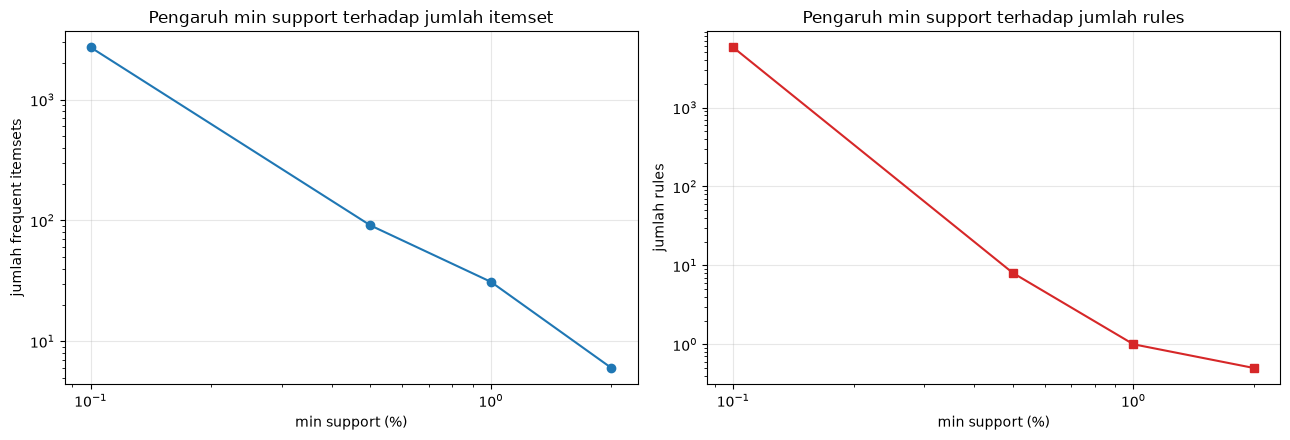

Distribusi ukuran itemset pada min support 0,1%: {1: 601, 2: 605, 3: 714, 4: 558, 5: 207, 6: 27, 7: 1}


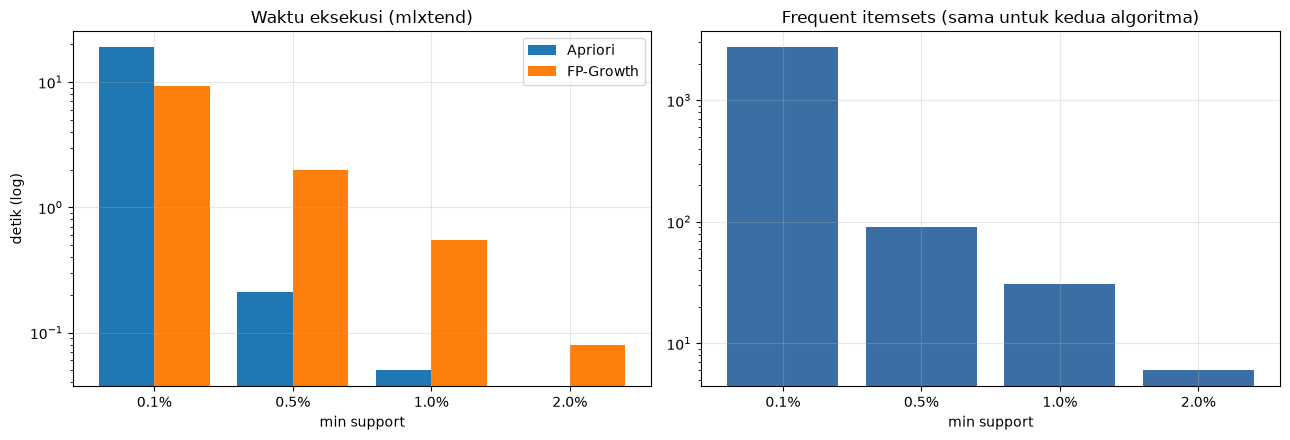

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(perf.min_support * 100, perf.frequent_itemsets_total, "o-"); ax[0].set(xscale="log", yscale="log", xlabel="min support (%)", ylabel="jumlah frequent itemsets", title="Pengaruh min support terhadap jumlah itemset")
ax[1].plot(perf.min_support * 100, perf.association_rules.clip(lower=0.5), "s-", color="C3"); ax[1].set(xscale="log", yscale="log", xlabel="min support (%)", ylabel="jumlah rules", title="Pengaruh min support terhadap jumlah rules")
plt.tight_layout(); plt.show()
print("Distribusi ukuran itemset pada min support 0,1%:", FI[SUPPORTS[0]].k.value_counts().sort_index().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(perf)); lab = [f"{s:.1%}" for s in perf.min_support]
ax[0].bar(x - .2, perf.apriori_detik, .4, label="Apriori"); ax[0].bar(x + .2, perf.fpgrowth_detik, .4, label="FP-Growth")
ax[0].set_xticks(x, lab); ax[0].set(yscale="log", xlabel="min support", ylabel="detik (log)", title="Waktu eksekusi (mlxtend)"); ax[0].legend()
ax[1].bar(x, perf.frequent_itemsets_total, color="#3b6ea5"); ax[1].set_xticks(x, lab); ax[1].set(yscale="log", xlabel="min support", title="Frequent itemsets (sama untuk kedua algoritma)")
plt.tight_layout(); plt.show()

## 9. Association Rule Mining (Task 5)
`min confidence = 50%`. **Support** = proporsi author yang publikasi di semua konferensi dalam rule; **confidence** = P(konsekuen | antecedent); **lift** = confidence / support konsekuen (lift > 1 → asosiasi positif, lebih sering muncul bersama daripada kebetulan).

In [15]:
for sup in SUPPORTS:
    r = RULES[sup]
    if len(r) == 0:
        print(f"\nmin_support {sup:.1%}: tidak ada rule dengan confidence >= {MIN_CONF:.0%}"); continue
    r = r.assign(antecedents=r.antecedents.map(fmt), consequents=r.consequents.map(fmt)).sort_values("lift", ascending=False)
    r.to_csv(OUT/f"t5_rules_sup{sup}.csv", index=False)
    print(f"\n===== min_support {sup:.1%}: {len(r)} rules (confidence >= 50%) - Top 10 lift =====")
    display(r.head(10)[["antecedents", "consequents", "support", "confidence", "lift"]].reset_index(drop=True))


===== min_support 0.1%: 5798 rules (confidence >= 50%) - Top 10 lift =====


,antecedents,consequents,support,confidence,lift
0,AAAI + ECCV + ICLR,CVPR + ICCV + ICML + NIPS,0.001028,0.504639,214.988418
1,EMNLP + IJCAI + NIPS,AAAI + ACL + ICLR,0.001022,0.504095,213.247650
2,AAAI + ECCV + ICLR + NIPS,CVPR + ICCV + ICML,0.001028,0.566604,209.977425
3,EMNLP + ICLR + IJCAI,AAAI + ACL + NIPS,0.001022,0.645103,209.964911
4,ACL + IJCAI + NIPS,AAAI + EMNLP + ICLR,0.001022,0.519197,208.712735
5,AAAI + CVPR + ICCV + ICLR,ECCV + ICML + NIPS,0.001028,0.504781,207.993933
6,ACL + ICLR + IJCAI,AAAI + EMNLP + NIPS,0.001022,0.663076,206.904294
7,AAAI + ECCV + ICML,CVPR + ICCV + ICLR + NIPS,0.001028,0.560237,203.260391
8,AAAI + CVPR + ICCV + ICML,ECCV + ICLR + NIPS,0.001028,0.565711,200.822462
9,AAAI + CVPR + ECCV + ICLR,ICCV + ICML + NIPS,0.001028,0.564821,200.628889



===== min_support 0.5%: 8 rules (confidence >= 50%) - Top 10 lift =====


,antecedents,consequents,support,confidence,lift
0,ICLR + NIPS,ICML,0.006001,0.604780,34.774365
1,ICML + NIPS,ICLR,0.006001,0.581096,34.414513
2,ACL,EMNLP,0.008020,0.500339,27.279493
3,ICLR + ICML,NIPS,0.006001,0.818118,26.487455
4,ECCV,CVPR,0.007592,0.596186,23.596152
5,ICCV,CVPR,0.008407,0.583572,23.096910
6,ICML,NIPS,0.010326,0.593749,19.223267
7,ICLR,NIPS,0.009922,0.587605,19.024341



===== min_support 1.0%: 1 rules (confidence >= 50%) - Top 10 lift =====


,antecedents,consequents,support,confidence,lift
0,ICML,NIPS,0.010326,0.593749,19.223267



min_support 2.0%: tidak ada rule dengan confidence >= 50%


Rule 1-ke-1 (pasangan konferensi) dengan lift tertinggi, min_support 0,1%:


,antecedents,consequents,support,confidence,lift
0,ECOC,OFC,0.002570,0.664445,77.806743
1,ASRU,INTERSPEECH,0.001120,0.731762,72.844414
2,SPAWC,ICC,0.001137,0.550319,38.095679
3,EACL,ACL,0.001688,0.604017,37.681696
4,CORL,ICRA,0.001217,0.597132,37.600174
5,SPAWC,GLOBECOM,0.001080,0.522595,35.579743
6,EACL,EMNLP,0.001735,0.620824,33.848544
7,NAACL,ACL,0.004339,0.535184,33.387551
8,ACMDIS,CHI,0.001820,0.560416,32.975015
9,IJCNLP,ACL,0.001092,0.513739,32.049691


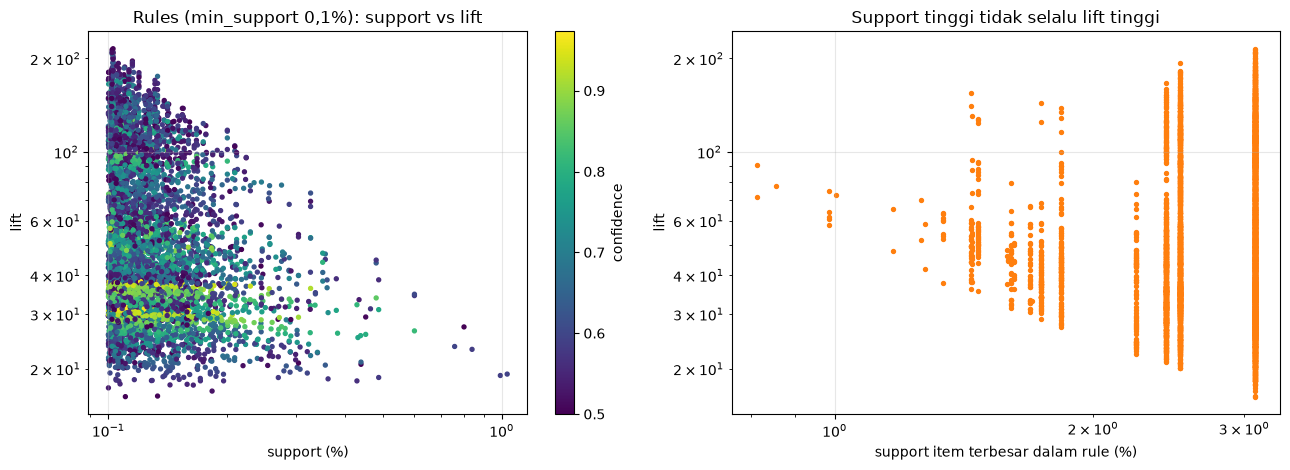

Korelasi Spearman (support item terbesar vs lift): 0.094


In [16]:
r = RULES[SUPPORTS[0]].copy()
r["n_ant"] = r.antecedents.map(len); r["n_con"] = r.consequents.map(len)
print("Rule 1-ke-1 (pasangan konferensi) dengan lift tertinggi, min_support 0,1%:")
r1 = r[(r.n_ant == 1) & (r.n_con == 1)].sort_values("lift", ascending=False).head(15)
display(r1.assign(antecedents=r1.antecedents.map(fmt), consequents=r1.consequents.map(fmt))[["antecedents", "consequents", "support", "confidence", "lift"]].reset_index(drop=True))

ff = FI[SUPPORTS[0]]; f1 = ff[ff.k == 1]; sup1 = dict(zip(f1.itemsets.map(lambda s: next(iter(s))), f1.support))
r["max_item_support"] = [max(sup1.get(i, 0) for i in a | c) for a, c in zip(r.antecedents, r.consequents)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sc = ax[0].scatter(r.support * 100, r.lift, c=r.confidence, s=8, cmap="viridis"); plt.colorbar(sc, ax=ax[0], label="confidence")
ax[0].set(xscale="log", yscale="log", xlabel="support (%)", ylabel="lift", title="Rules (min_support 0,1%): support vs lift")
ax[1].scatter(r.max_item_support * 100, r.lift, s=8, color="C1"); ax[1].set(xscale="log", yscale="log", xlabel="support item terbesar dalam rule (%)", ylabel="lift", title="Support tinggi tidak selalu lift tinggi")
plt.tight_layout(); plt.show()
print("Korelasi Spearman (support item terbesar vs lift): %.3f" % spearmanr(r.max_item_support, r.lift)[0])

## 10. Validasi Silang: Implementasi Sendiri vs Library
Implementasi sendiri (Apriori & FP-Growth) dibandingkan dengan mlxtend pada **sampel acak 300.000 author** (min support 1% dan 2%) agar cepat.

In [17]:
rng = np.random.default_rng(42)
idx = np.sort(rng.choice(N_AB, size=300_000, replace=False)); Xs = X_ab[idx]
tx_s = [frozenset(venues[Xs.indices[Xs.indptr[i]:Xs.indptr[i + 1]]]) for i in range(Xs.shape[0])]
rows = []
for sup in [0.005, 0.01, 0.02]:
    t0 = time.perf_counter(); oa, n = apriori(tx_s, sup); ta = time.perf_counter() - t0
    t0 = time.perf_counter(); of, _ = fpgrowth(tx_s, sup); tf = time.perf_counter() - t0
    lib, _ = run_algo(Xs, sup, "fpgrowth"); libs = {frozenset(s) for s in lib.itemsets}
    rows.append({"min_support": sup, "own_apriori_s": round(ta, 2), "own_fpgrowth_s": round(tf, 2), "itemsets_own": len(of),
                 "itemsets_lib": len(libs), "identik(own_apriori=own_fpg=lib)": set(oa) == set(of) == libs,
                 "rules_own": len(association_rules(of, n, MIN_CONF)), "rules_lib": len(get_rules(lib, Xs.shape[0]))})
display(pd.DataFrame(rows))
del tx_s, Xs

,min_support,own_apriori_s,own_fpgrowth_s,itemsets_own,itemsets_lib,identik(own_apriori=own_fpg=lib),rules_own,rules_lib
0,0.005,0.63,0.53,93,93,True,8,8
1,0.010,0.36,0.44,31,31,True,1,1
2,0.020,0.26,0.33,6,6,True,0,0


Catatan performa implementasi sendiri pada **data penuh** (diukur terpisah dengan skrip `src/analysis.py`; itemset identik dengan library): pada min support 0,1% Apriori buatan sendiri membutuhkan ± **3.933 detik**, sedangkan FP-Growth buatan sendiri hanya ± **12,7 detik**; pada support ≥ 0,5% keduanya selesai dalam hitungan detik.

## 11. Author-Year-Based DB: Frequent Pattern & Rules (Perbandingan Representasi)
Min support 0,1% dan 0,5% pada Author-Year-Based, untuk menjawab: *apakah pola Author-Based dan Author-Year-Based berbeda?*

In [18]:
N_AY = X_ay.shape[0]; FI_AY, RU_AY = {}, {}
for sup in [0.001, 0.005]:
    fi, _ = run_algo(X_ay, sup, "fpgrowth"); RU_AY[sup] = get_rules(fi, N_AY); FI_AY[sup] = fi
    print(f"Author-Year min_support {sup:.1%}: itemsets={len(fi)} (k1={(fi.k==1).sum()}, k2={(fi.k==2).sum()}, k3={(fi.k==3).sum()}), rules={len(RU_AY[sup])}")
cmp = []
for sup in [0.001, 0.005]:
    a, b = FI[sup], FI_AY[sup]
    cmp.append({"min_support": sup, "AB_itemsets": len(a), "AY_itemsets": len(b), "AB_rules": len(RULES[sup]), "AY_rules": len(RU_AY[sup]),
                "AB_pairs(k=2)": int((a.k == 2).sum()), "AY_pairs(k=2)": int((b.k == 2).sum())})
display(pd.DataFrame(cmp))
print("Top 10 pasangan konferensi - Author-Year-Based (min_support 0,1%):"); display(show_top(FI_AY[0.001], k=2, n=N_AY))
print("Top 10 pasangan konferensi - Author-Based (min_support 0,1%):"); display(show_top(FI[0.001], k=2, n=N_AB))
r_ay = RU_AY[0.001]
if len(r_ay):
    x = r_ay.assign(antecedents=r_ay.antecedents.map(fmt), consequents=r_ay.consequents.map(fmt)).sort_values("lift", ascending=False)
    print("Top 10 rules (lift) Author-Year-Based, min_support 0,1%:"); display(x.head(10)[["antecedents", "consequents", "support", "confidence", "lift"]].reset_index(drop=True))
    ab_set = {(frozenset(a), frozenset(c)) for a, c in zip(RULES[0.001].antecedents, RULES[0.001].consequents)}
    ay_set = {(frozenset(a), frozenset(c)) for a, c in zip(r_ay.antecedents, r_ay.consequents)}
    print(f"Rule ada di kedua representasi: {len(ab_set & ay_set)} | hanya Author-Based: {len(ab_set - ay_set)} | hanya Author-Year: {len(ay_set - ab_set)}")

Author-Year min_support 0.1%: itemsets=393 (k1=316, k2=68, k3=9), rules=10


Author-Year min_support 0.5%: itemsets=43 (k1=43, k2=0, k3=0), rules=0


,min_support,AB_itemsets,AY_itemsets,AB_rules,AY_rules,AB_pairs(k=2),AY_pairs(k=2)
0,0.001,2713,393,5798,10,605,68
1,0.005,91,43,8,0,21,0


Top 10 pasangan konferensi - Author-Year-Based (min_support 0,1%):


,itemset,k,count,support
0,ICML + NIPS,2,18300,0.004709
1,ICLR + NIPS,2,17065,0.004391
2,CVPR + NIPS,2,15783,0.004061
3,ACL + EMNLP,2,15546,0.004000
4,AAAI + NIPS,2,13579,0.003494
5,CVPR + ICCV,2,12705,0.003269
6,ICLR + ICML,2,11583,0.002980
7,GLOBECOM + ICC,2,11577,0.002979
8,AAAI + CVPR,2,11530,0.002967
9,CVPR + ECCV,2,10301,0.002651


Top 10 pasangan konferensi - Author-Based (min_support 0,1%):


,itemset,k,count,support
0,ICML + NIPS,2,18028,0.010326
1,ICLR + NIPS,2,17322,0.009922
2,AAAI + NIPS,2,15421,0.008833
3,CVPR + NIPS,2,15246,0.008733
4,CVPR + ICCV,2,14678,0.008407
5,ACL + EMNLP,2,14002,0.008020
6,CVPR + ECCV,2,13255,0.007592
7,ICLR + ICML,2,12805,0.007335
8,ICRA + IROS,2,11812,0.006766
9,AAAI + CVPR,2,11804,0.006761


Top 10 rules (lift) Author-Year-Based, min_support 0,1%:


,antecedents,consequents,support,confidence,lift
0,AAAI + EMNLP,ACL,0.001089,0.530451,44.908486
1,EMNLP + NIPS,ACL,0.001200,0.510008,43.177723
2,AAAI + ACL,EMNLP,0.001089,0.555658,41.207627
3,ACL + NIPS,EMNLP,0.001200,0.537522,39.862656
4,ICCV + NIPS,CVPR,0.001231,0.597030,28.487082
5,CVPR + ICML,NIPS,0.001156,0.636621,26.746877
6,AAAI + ICLR,NIPS,0.001139,0.635607,26.704245
7,ICLR + ICML,NIPS,0.001881,0.631270,26.522046
8,AAAI + ICML,NIPS,0.001223,0.620901,26.086423
9,CVPR + ICLR,NIPS,0.001344,0.601243,25.260510


Rule ada di kedua representasi: 10 | hanya Author-Based: 5788 | hanya Author-Year: 0


## 12. Temporal Association Analysis (Bagian E)
Author-Year-Based DB dibagi per periode (2015–2017, 2018–2020, 2021–2023, 2024–2025). Pada uji awal dengan min support 0,5%, hampir tidak ada rule (0–1 rule per periode, karena transaksi didominasi 1-item), sehingga dipakai **min support 0,1%** dan **min confidence 50%**, sama untuk semua periode agar bisa dibandingkan.

In [19]:
per_fi, per_ru = {}, {}
for a, b in PERIODS:
    m = (ay_year >= a) & (ay_year <= b); Xp = X_ay[np.where(m)[0]]; n = Xp.shape[0]
    fi, el = run_algo(Xp, TEMPORAL_SUPPORT, "fpgrowth"); r = get_rules(fi, n)
    per_fi[(a, b)], per_ru[(a, b)] = fi, r
    print(f"{a}-{b}: transaksi={n:,} | frequent itemsets={len(fi)} (k1={(fi.k==1).sum()}, k2={(fi.k==2).sum()}, k>=3={(fi.k>=3).sum()}) | rules={len(r)} | {el:.1f}s")
tab = pd.DataFrame([{"periode": f"{a}-{b}", "transaksi": int(((ay_year >= a) & (ay_year <= b)).sum()), "frequent_itemsets": len(per_fi[(a, b)]),
                     "pasangan(k=2)": int((per_fi[(a, b)].k == 2).sum()), "rules": len(per_ru[(a, b)])} for a, b in PERIODS]); display(tab)

2015-2017: transaksi=885,369 | frequent itemsets=389 (k1=372, k2=17, k>=3=0) | rules=1 | 0.6s


2018-2020: transaksi=1,031,221 | frequent itemsets=360 (k1=331, k2=29, k>=3=0) | rules=0 | 1.1s


2021-2023: transaksi=1,132,426 | frequent itemsets=421 (k1=338, k2=72, k>=3=11) | rules=11 | 1.2s


2024-2025: transaksi=837,344 | frequent itemsets=803 (k1=307, k2=225, k>=3=271) | rules=422 | 1.4s


,periode,transaksi,frequent_itemsets,pasangan(k=2),rules
0,2015-2017,885369,389,17,1
1,2018-2020,1031221,360,29,0
2,2021-2023,1132426,421,72,11
3,2024-2025,837344,803,225,422


In [20]:
key = lambda r: {(tuple(sorted(a)), tuple(sorted(c))) for a, c in zip(r.antecedents, r.consequents)}
K = {p: key(r) for p, r in per_ru.items()}
stable = set.intersection(*K.values()); union = set.union(*K.values())
print(f"Total rule unik lintas periode: {len(union)} | muncul di SEMUA periode (bertahan): {len(stable)}")
cnt_periode = Counter(sum(k in K[p] for p in PERIODS) for k in union)
print("Distribusi: rule muncul di berapa periode ->", dict(sorted(cnt_periode.items())))

def lift_map(r): return {(tuple(sorted(a)), tuple(sorted(c))): l for a, c, l in zip(r.antecedents, r.consequents, r.lift)}
LM = {p: lift_map(r) for p, r in per_ru.items()}
st = sorted(stable, key=lambda k: -np.mean([LM[p][k] for p in LM]))[:15]
print("\nContoh rule yang bertahan di semua periode (lift rata-rata tertinggi):")
display(pd.DataFrame([{"rule": f"{' + '.join(k[0])} -> {' + '.join(k[1])}", **{f"lift {a}-{b}": round(LM[(a, b)][k], 1) for a, b in PERIODS}} for k in st]))

Total rule unik lintas periode: 423 | muncul di SEMUA periode (bertahan): 0
Distribusi: rule muncul di berapa periode -> {1: 412, 2: 11}

Contoh rule yang bertahan di semua periode (lift rata-rata tertinggi):


""


Rule BARU di 2024-2025 (tidak ada di periode sebelumnya): 411
Rule yang HILANG setelah 2015-2017 (hanya ada di periode awal): 1

Contoh rule baru:


,rule,lift
0,AAAI + EMNLP + ICLR -> ACL + NIPS,89.6
1,AAAI + ACL + ICLR -> EMNLP + NIPS,83.8
2,EMNLP + ICLR + ICML -> ACL + NIPS,82.1
3,ACL + ICLR + ICML -> EMNLP + NIPS,81.9
4,ICLR + IJCAI -> AAAI + NIPS,63.9
5,ICML + MM -> AAAI + NIPS,62.5
6,ICML + IJCAI -> AAAI + NIPS,62.4
7,AAAI + ICLR + ICML -> CVPR + NIPS,53.5
8,AAAI + ACL + ICML -> ICLR + NIPS,53.2
9,AAAI + EMNLP + ICML -> ICLR + NIPS,52.1


Contoh rule yang hilang:


,rule,lift
0,ECOC -> OFC,57.8


Top-5 pasangan konferensi 2015-2017: GLOBECOM + ICC (0.35%); AMCC + CDC (0.21%); ICRA + IROS (0.20%); ECOC + OFC (0.19%); GLOBECOM + VTC (0.19%)
Top-5 pasangan konferensi 2018-2020: CVPR + ECCV (0.30%); GLOBECOM + ICC (0.28%); ICML + NIPS (0.26%); AAAI + IJCAI (0.23%); ICRA + IROS (0.22%)
Top-5 pasangan konferensi 2021-2023: ICML + NIPS (0.50%); CVPR + NIPS (0.47%); ACL + EMNLP (0.47%); ICLR + NIPS (0.46%); CVPR + ICCV (0.46%)
Top-5 pasangan konferensi 2024-2025: ICLR + NIPS (1.15%); ICML + NIPS (1.08%); CVPR + NIPS (0.94%); ACL + EMNLP (0.87%); AAAI + NIPS (0.82%)


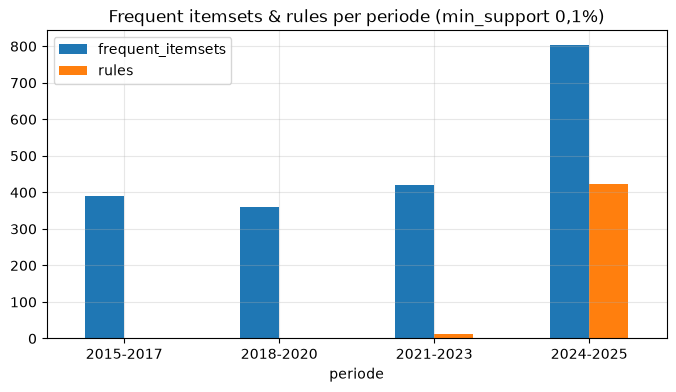

In [21]:
first, last = PERIODS[0], PERIODS[-1]
new_rules = K[last] - set.union(*[K[p] for p in PERIODS[:-1]])
gone = K[first] - set.union(*[K[p] for p in PERIODS[1:]])
print(f"Rule BARU di {last[0]}-{last[1]} (tidak ada di periode sebelumnya): {len(new_rules)}")
print(f"Rule yang HILANG setelah {first[0]}-{first[1]} (hanya ada di periode awal): {len(gone)}")
f = lambda k: f"{' + '.join(k[0])} -> {' + '.join(k[1])}"
nr = sorted(new_rules, key=lambda k: -LM[last][k])[:10]; gr_ = sorted(gone, key=lambda k: -LM[first][k])[:10]
print("\nContoh rule baru:"); display(pd.DataFrame({"rule": [f(k) for k in nr], "lift": [round(LM[last][k], 1) for k in nr]}))
print("Contoh rule yang hilang:"); display(pd.DataFrame({"rule": [f(k) for k in gr_], "lift": [round(LM[first][k], 1) for k in gr_]}))
for p in PERIODS:
    fi = per_fi[p]; t = fi[fi.k == 2].sort_values("support", ascending=False).head(5)
    print(f"Top-5 pasangan konferensi {p[0]}-{p[1]}:", "; ".join(f"{fmt(s)} ({sp:.2%})" for s, sp in zip(t.itemsets, t.support)))
    if len(per_ru[p]):
        per_ru[p].assign(antecedents=per_ru[p].antecedents.map(fmt), consequents=per_ru[p].consequents.map(fmt)).sort_values("lift", ascending=False).to_csv(OUT/f"temporal_rules_{p[0]}_{p[1]}.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4)); tab.set_index("periode")[["frequent_itemsets", "rules"]].plot.bar(ax=ax, title="Frequent itemsets & rules per periode (min_support 0,1%)"); plt.xticks(rotation=0); plt.show()

## 13. Keterbatasan Dataset & Asumsi
- **Venue = akronim key DBLP.** Venue dengan akronim berbeda tetapi satu "seri" diperlakukan sebagai venue terpisah; sebaliknya satu akronim bisa mencakup beberapa jenis acara.
- **Workshop** tidak dipisahkan sebagai item sendiri (dipakai key `conf/*`); sebagian workshop menumpang di bawah akronim konferensi induk.
- **Identitas author** hanya dinormalisasi berdasarkan nama + nomor disambiguasi DBLP. Nama yang sama untuk orang berbeda (atau satu orang dengan variasi nama) tetap mungkin tercampur.
- **Popularitas = aktivitas publikasi** (jumlah paper dan author unik), bukan kualitas/sitasi.
- **Data 2025 kemungkinan belum lengkap** (proceeding akhir tahun belum seluruhnya masuk DBLP saat pengambilan 19 November 2026); terlihat dari venue seperti IGARSS dan EMBC yang tercatat 0 publikasi pada 2025. Venue dua-tahunan (biennial) juga tidak muncul pada tahun ganjil/genap tertentu sehingga perbandingan 2015 vs 2025 untuk venue tersebut tidak adil.
- **Transaksi didominasi 1-item**: sebagian besar author hanya publikasi di satu konferensi, sehingga support pasangan konferensi kecil dan min support tinggi (1–2%) menghasilkan sangat sedikit pola.
- **Konferensi lintas bidang:** karena memakai seluruh Computer Science, konferensi besar di bidang berbeda (signal processing, robotik, HCI, dll.) muncul bersama konferensi AI.

## 14. Kesimpulan
Seluruh kesimpulan berikut berasal dari hasil eksperimen di atas (DBLP, `inproceedings` 2015–2025: **1.997.196 publikasi**, **1.745.848 author unik**, **4.372 venue**).

**1. Konferensi dengan popularitas publikasi tertinggi.** **NIPS** (NeurIPS): 25.455 publikasi dan 53.924 author unik, keduanya peringkat 1. Berikutnya CVPR (22.750), ICASSP (21.606), HCI (19.912), IGARSS (19.685). Delapan dari sepuluh venue teratas sama pada ranking publikasi dan ranking author unik; yang berbeda: CHI dan ICC hanya ada di top-10 publikasi, sedangkan ICML dan IROS hanya ada di top-10 author. Korelasi Spearman publikasi vs author unik seluruh venue = 0,987, jadi kedua ukuran popularitas sangat searah. Tren 2015→2025: NIPS naik dari 440 ke 5.823 publikasi (±13×), EMNLP 324 → 3.491, CVPR 733 → 3.543, AAAI 790 → 3.508; venue AI/ML tumbuh paling cepat (ICLR tumbuh ±25× antara 2015–17 dan 2023–25), sedangkan ICC menurun tipis (1.747 → 1.479). IGARSS dan EMBC tercatat 0 pada 2025 — kemungkinan karena data 2025 belum lengkap atau siklus dua-tahunan, bukan karena benar-benar hilang.

**2. Apakah yang paling populer juga punya asosiasi terkuat?** Sebagian. NIPS paling sering muncul bersama konferensi lain (ICML+NIPS, ICLR+NIPS, AAAI+NIPS, CVPR+NIPS adalah pasangan dengan support tertinggi), dan satu-satunya rule yang bertahan pada min support 1% adalah ICML → NIPS (confidence 59,4%, lift 19,2). Tetapi asosiasi **terkuat menurut lift** justru dimiliki venue yang lebih kecil dan sempit bidangnya, mis. ECOC → OFC (lift 77,8), ASRU → INTERSPEECH (72,8), EACL → ACL (37,7). Korelasi support vs lift lemah (Spearman 0,094): support tinggi tidak menjamin lift tinggi.

**3. Kombinasi konferensi yang paling sering muncul bersama** (Author-Based, jumlah author): ICML+NIPS (18.028), ICLR+NIPS (17.322), AAAI+NIPS (15.421), CVPR+NIPS (15.246), CVPR+ICCV (14.678), ACL+EMNLP (14.002), CVPR+ECCV (13.255), ICLR+ICML (12.805), ICRA+IROS (11.812), AAAI+CVPR (11.804). Hampir semuanya pasangan dalam satu bidang yang sama (ML, visi komputer, NLP, robotika).

**4. Rule dengan lift tertinggi dan maknanya.** Pada min support 0,1% (5.798 rules): `AAAI + ECCV + ICLR → CVPR + ICCV + ICML + NIPS` (support 0,103%, confidence 50,5%, lift 215). Artinya, author yang pernah publikasi di AAAI, ECCV, dan ICLR kira-kira 215× lebih mungkin juga publikasi di CVPR, ICCV, ICML, dan NIPS dibanding author acak — yaitu komunitas inti peneliti AI/ML/visi yang aktif di banyak venue papan atas. Perlu hati-hati: lift sangat besar untuk rule panjang karena itemset konsekuennya langka dan support rule hanya sedikit di atas ambang (±0,1%). Untuk rule pasangan (1-ke-1), lift tertinggi: ECOC → OFC (77,8; komunitas komunikasi optik) dan ASRU → INTERSPEECH (72,8; komunitas pengenalan suara).

**5. Perbedaan pola Author-Based vs Author-Year-Based.** Author-Based jauh lebih kaya: pada min support 0,1% terdapat 2.713 frequent itemsets dan 5.798 rules, dibanding 393 itemsets dan 10 rules pada Author-Year-Based; pada 0,5%: 91 itemsets/8 rules vs 43/0. Seluruh 10 rule Author-Year juga ditemukan di Author-Based, dan tidak ada rule yang hanya muncul di Author-Year. Peringkat pasangan teratas hampir sama (ICML+NIPS, ICLR+NIPS, CVPR+NIPS, ACL+EMNLP), tetapi pada Author-Year muncul GLOBECOM+ICC di sepuluh besar. Penyebabnya: Author-Year hanya menangkap kombinasi venue dalam **satu tahun**, sehingga pola jangka panjang (itemset ≥ 4 venue) hampir tidak muncul; di sisi lain representasi ini memungkinkan analisis temporal.

**6. Algoritma dengan performa terbaik.** Apriori dan FP-Growth selalu menghasilkan frequent itemsets yang **identik** pada keempat min support (2.713 / 91 / 31 / 6 itemset; rules 5.798 / 8 / 1 / 0), dan identik juga dengan implementasi buatan sendiri. Waktu (mlxtend, data tereduksi): pada 0,1% FP-Growth 9,4 detik vs Apriori 18,0 detik; pada 0,5–2% Apriori justru lebih cepat (0,21 / 0,05 / 0,00 detik vs 1,96 / 0,56 / 0,08 detik) karena kandidat sangat sedikit dan FP-Growth memiliki overhead pembangunan tree. Pada implementasi sendiri di data penuh perbedaannya lebih ekstrem: 0,1% Apriori ± 3.933 detik vs FP-Growth ± 12,7 detik. Kesimpulan: **FP-Growth lebih sesuai untuk DBLP** karena skalabilitasnya pada min support rendah (kondisi yang dibutuhkan agar pola antar-konferensi muncul); Apriori cukup pada min support tinggi.

**7. Insight utama.**
- Hampir 59% author hanya publikasi di satu konferensi, sehingga pola asosiasi baru muncul pada min support sangat rendah (≤ 0,5%); pada 1–2% hanya tersisa venue tunggal dan satu rule (ICML → NIPS).
- Asosiasi antar-konferensi mengikuti **klaster bidang**: ML/AI (NIPS, ICML, ICLR, AAAI, IJCAI), visi komputer (CVPR, ICCV, ECCV), NLP (ACL, EMNLP, NAACL, EACL), robotika (ICRA, IROS), komunikasi (GLOBECOM, ICC, VTC), optik (ECOC, OFC), suara (ASRU, INTERSPEECH).
- **Temporal** (Author-Year, min support 0,1%): jumlah rule per periode 1 → 0 → 11 → 422 (2015–17, 2018–20, 2021–23, 2024–25), dan **tidak ada rule yang bertahan di keempat periode**. Pasangan teratas bergeser dari komunikasi/kontrol (GLOBECOM+ICC 0,35%, AMCC+CDC pada 2015–17) ke ML/AI (ICLR+NIPS 1,15%, ICML+NIPS 1,08% pada 2024–25): semakin banyak author yang dalam satu tahun yang sama publikasi di beberapa venue AI papan atas, sejalan dengan ledakan publikasi NIPS/ICLR/AAAI. Rule "baru" di 2024–25 (411) didominasi kombinasi AAAI/ACL/EMNLP/ICLR/ICML/NIPS. Karena data 2025 belum tentu lengkap dan konferensi tertentu bersiklus dua-tahunan, interpretasi tren perlu hati-hati.
